In [2]:
!pip install catboost lightgbm xgboost -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
import lightgbm as lgb
from xgboost import XGBClassifier

def make_churn(n_samples=60000, random_state=42):
    rng = np.random.RandomState(random_state)
    cities = ['Toshkent', 'Samarqand', 'Buxoro', 'Fargona', 'Andijon', 'Namangan']
    devices = ['Android', 'iOS', 'Web']
    tariffs = ['Start', 'Standard', 'Premium', 'VIP']

    df = pd.DataFrame({
        'age': rng.randint(18, 70, size=n_samples),
        'balance': np.round(rng.exponential(50000, size=n_samples), 2),
        'city': rng.choice(cities, size=n_samples, p=[0.4, 0.15, 0.15, 0.1, 0.1, 0.1]),
        'device': rng.choice(devices, size=n_samples, p=[0.6, 0.3, 0.1]),
        'tariff': rng.choice(tariffs, size=n_samples, p=[0.4, 0.35, 0.2, 0.05]),
        'product_id': rng.randint(1000, 3000, size=n_samples).astype(str),
        'customer_id': [f"C{100000 + i}" for i in range(n_samples)]
    })

    logit = (
        -1.5
        + (df['tariff'] == 'Start') * 0.8
        - (df['tariff'] == 'VIP') * 1.2
        + (df['device'] == 'Android') * 0.4
        - (df['age'] - 40) * 0.02
        + (df['product_id'].astype(int) % 10 == 0) * 1.1
    )
    prob = 1 / (1 + np.exp(-logit))
    df['churn'] = rng.binomial(1, prob)
    return df

df = make_churn()
print("Jadval o'lchami:", df.shape)
display(df.head())


# datani yaratdik va head qismini ko'rdik!

Jadval o'lchami: (60000, 8)


,age,balance,city,device,tariff,product_id,customer_id,churn
0,56,9484.00,Andijon,Android,Premium,2262,C100000,0
1,69,11539.63,Toshkent,iOS,Start,2340,C100001,0
2,46,56404.38,Samarqand,Android,Standard,2598,C100002,1
3,32,2248.73,Toshkent,Android,Premium,1775,C100003,1
4,60,85930.89,Namangan,iOS,Premium,1958,C100004,0


In [3]:
df.shape

(60000, 8)

In [4]:
X = df.drop(columns="churn")
y = df["churn"]

cats = ["city", "device", "tariff", "product_id", "customer_id"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

In [5]:
X_tr_te = X_train.copy()
X_te_te = X_test.copy()

global_mean = y_train.mean()

for col in cats:
    means = y_train.groupby(X_train[col]).mean()
    X_tr_te[col] = X_train[col].map(means)
    X_te_te[col] = X_test[col].map(means).fillna(global_mean)

lgb_te = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)
lgb_te.fit(X_tr_te, y_train)

te_train_auc = roc_auc_score(y_train, lgb_te.predict_proba(X_tr_te)[:, 1])
te_test_auc  = roc_auc_score(y_test,  lgb_te.predict_proba(X_te_te)[:, 1])

print(f"Train AUC: {te_train_auc:.4f}")
print(f"Test AUC:  {te_test_auc:.4f}")

Train AUC: 1.0000
Test AUC:  0.5325


0:	test: 0.6264892	best: 0.6264892 (0)	total: 247ms	remaining: 12m 19s
200:	test: 0.6614146	best: 0.6615477 (176)	total: 21.4s	remaining: 4m 57s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6617205677
bestIteration = 262

Shrink model to first 263 iterations.

CatBoost Best Iteration: 262
Train AUC:   0.6863
Test AUC:    0.6587


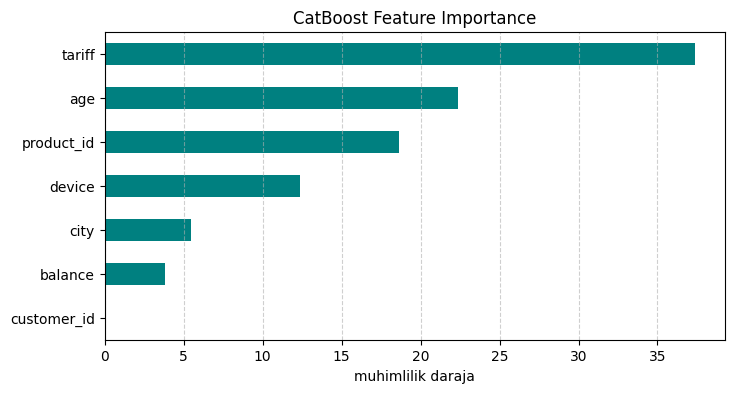

In [6]:
cb_model = CatBoostClassifier(
    iterations=3000,
    learning_rate=0.05,
    depth=6,
    eval_metric="AUC",
    random_seed=42,
    verbose=200
)

cb_model.fit(
    X_train, y_train,
    cat_features=cats,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100
)

cb_train_auc = roc_auc_score(y_train, cb_model.predict_proba(X_train)[:, 1])
cb_test_auc  = roc_auc_score(y_test,  cb_model.predict_proba(X_test)[:, 1])

print("\n" + "="*45)
print(f"CatBoost Best Iteration: {cb_model.get_best_iteration()}")
print(f"Train AUC:   {cb_train_auc:.4f}")
print(f"Test AUC:    {cb_test_auc:.4f}")
print("="*45)

# Feature Importance grafig
imp = pd.Series(
    cb_model.get_feature_importance(),
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 4))
imp.plot.barh(color='teal')
plt.title("CatBoost Feature Importance")
plt.xlabel("muhimlilik daraja")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

In [10]:
X_tr_new = X_train.drop(columns=['customer_id']).assign(product_id=X_train['product_id'].astype(int))
X_va_new = X_valid.drop(columns=['customer_id']).assign(product_id=X_valid['product_id'].astype(int))
X_te_new = X_test.drop(columns=['customer_id']).assign(product_id=X_test['product_id'].astype(int))

model_int = CatBoostClassifier(iterations=3000, learning_rate=0.05, eval_metric="AUC", random_seed=42, verbose=False)

model_int.fit(
    X_tr_new, y_train,
    cat_features=["city", "device", "tariff"],
    eval_set=(X_va_new, y_valid),
    early_stopping_rounds=100
)

int_test_auc = roc_auc_score(y_test, model_int.predict_proba(X_te_new)[:, 1])

print("LightGBM Test AUC:", round(te_test_auc, 4))
print("CatBoost (To'g'ri)   Test AUC:", round(cb_test_auc, 4))
print("CatBoost (int)       Test AUC:", round(int_test_auc, 4))

LightGBM Test AUC: 0.5325
CatBoost (To'g'ri)   Test AUC: 0.6587
CatBoost (int)       Test AUC: 0.6504


In [17]:
df = sns.load_dataset('titanic')

ustunlar = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df[ustunlar + ['survived']].copy()

df['age'] = df['age'].fillna(28)
df['embarked'] = df['embarked'].fillna('S')

for ustun in ['pclass', 'sex', 'embarked']:
    df[ustun] = df[ustun].astype(str)
df.shape

(891, 8)

In [19]:
X = df[ustunlar]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [22]:
model_cb = CatBoostClassifier(iterations=300, verbose=False, random_seed=42)
model_cb.fit(X_train, y_train, cat_features=['pclass', 'sex', 'embarked'])

ball_cb = roc_auc_score(y_test, model_cb.predict_proba(X_test)[:, 1])


for ustun in ['pclass', 'sex', 'embarked']:
    X_train[ustun] = X_train[ustun].astype('category')
    X_test[ustun] = X_test[ustun].astype('category')


model_lgb = lgb.LGBMClassifier(n_estimators=300, verbose=-1, random_seed=42)
model_lgb.fit(X_train, y_train)

ball_lgb = roc_auc_score(y_test, model_lgb.predict_proba(X_test)[:, 1])

model_xgb = XGBClassifier(n_estimators=300, enable_categorical=True, random_state=42)
model_xgb.fit(X_train, y_train)

ball_xgb = roc_auc_score(y_test, model_xgb.predict_proba(X_test)[:, 1])

print("CatBoost balli: ", round(ball_cb, 4))
print("LightGBM balli: ", round(ball_lgb, 4))
print("XGBoost balli:  ", round(ball_xgb, 4))

CatBoost balli:  0.886
LightGBM balli:  0.8752
XGBoost balli:   0.8647
